# 04 – Erster Blick: IFS-Kontrolllauf (ECMWF, Physik-Modell)

Der ungestörte Lauf (Member 0) des IFS-Ensembles, Start täglich 00 UTC, am nächsten Gitterpunkt zur Station.
Bis +144 h alle 3 Stunden, danach alle 6 Stunden. Einheiten wie bei AIFS: °C und Niederschlag als Rate in mm/s.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/full_datasets/ifs_control_hamburg_t2m_precip.csv",
                 parse_dates=["init_time", "valid_time"]
)

df.head()

,init_time,lead_time_h,valid_time,temperature_2m,precipitation_surface,ensemble_member,latitude,longitude
0,2024-04-01,0.0,2024-04-01 00:00:00,6.40625,NaN,0,53.75,10.0
1,2024-04-01,3.0,2024-04-01 03:00:00,6.40625,0.000000,0,53.75,10.0
2,2024-04-01,6.0,2024-04-01 06:00:00,7.40625,0.000000,0,53.75,10.0
3,2024-04-01,9.0,2024-04-01 09:00:00,9.81250,0.000091,0,53.75,10.0
4,2024-04-01,12.0,2024-04-01 12:00:00,9.68750,0.000542,0,53.75,10.0


In [2]:
print(f"Datensätze: {len(df):,}")

print("Erster Forecast:",
      df["init_time"].min())

print("Letzter Forecast:",
      df["init_time"].max())

Datensätze: 81,685
Erster Forecast: 2024-04-01 00:00:00
Letzter Forecast: 2026-11-17 00:00:00


## Welche Lead Times gibt es?

In [3]:
sorted(df["lead_time_h"].unique())

[np.float64(0.0),
 np.float64(3.0),
 np.float64(6.0),
 np.float64(9.0),
 np.float64(12.0),
 np.float64(15.0),
 np.float64(18.0),
 np.float64(21.0),
 np.float64(24.0),
 np.float64(27.0),
 np.float64(30.0),
 np.float64(33.0),
 np.float64(36.0),
 np.float64(39.0),
 np.float64(42.0),
 np.float64(45.0),
 np.float64(48.0),
 np.float64(51.0),
 np.float64(54.0),
 np.float64(57.0),
 np.float64(60.0),
 np.float64(63.0),
 np.float64(66.0),
 np.float64(69.0),
 np.float64(72.0),
 np.float64(75.0),
 np.float64(78.0),
 np.float64(81.0),
 np.float64(84.0),
 np.float64(87.0),
 np.float64(90.0),
 np.float64(93.0),
 np.float64(96.0),
 np.float64(99.0),
 np.float64(102.0),
 np.float64(105.0),
 np.float64(108.0),
 np.float64(111.0),
 np.float64(114.0),
 np.float64(117.0),
 np.float64(120.0),
 np.float64(123.0),
 np.float64(126.0),
 np.float64(129.0),
 np.float64(132.0),
 np.float64(135.0),
 np.float64(138.0),
 np.float64(141.0),
 np.float64(144.0),
 np.float64(150.0),
 np.float64(156.0),
 np.float64(162.0)

In [4]:
lead_times = sorted(df["lead_time_h"].unique())

print(f"Anzahl verschiedener Lead Times: {len(lead_times)}")

Anzahl verschiedener Lead Times: 85


85 Lead Times: 0–144 h alle 3 h, danach bis 360 h alle 6 h. Für die Temperatur nehmen wir später einfach die
6-h-Zeitpunkte; beim Niederschlag müssen wir die wechselnde Schrittlänge beachten (siehe unten).

In [5]:
forecast_sizes = (
    df.groupby("init_time")
      .size()
)

forecast_sizes.describe()

count    961.0
mean      85.0
std        0.0
min       85.0
25%       85.0
50%       85.0
75%       85.0
max       85.0
dtype: float64

In [6]:
EXPECTED_ROWS = 85

forecast_sizes[
    forecast_sizes != EXPECTED_ROWS
]

Series([], dtype: int64)

Jeder Lauf hat alle 85 Lead Times; innerhalb eines Laufs fehlen keine Zeitpunkte.

## Fehlende Werte

In [7]:
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "percent": df.isna().sum() / len(df) * 100
})

display(missing)

,count,percent
init_time,0,0.000000
lead_time_h,0,0.000000
valid_time,0,0.000000
temperature_2m,0,0.000000
precipitation_surface,961,1.176471
ensemble_member,0,0.000000
latitude,0,0.000000
longitude,0,0.000000


Wie bei AIFS fehlt nur der Niederschlag bei Lead Time 0 (961 Werte = 961 Läufe): Zum Startzeitpunkt gibt es noch
keinen Niederschlag.

## Sind alle Tage vorhanden?

In [8]:
expected_inits = pd.date_range(
    start=df["init_time"].min(),
    end=df["init_time"].max(),
    freq="D"
)

actual_inits = pd.DatetimeIndex(
    sorted(df["init_time"].unique())
)

missing_inits = expected_inits.difference(actual_inits)

print(f"Fehlende Forecast-Tage: {len(missing_inits)}")

missing_inits[:20]

Fehlende Forecast-Tage: 0


DatetimeIndex([], dtype='datetime64[ns]', freq='D')

## Temperaturverteilung

In [9]:
df["temperature_2m"].describe()

count    81685.000000
mean        10.803405
std          7.380206
min        -19.000000
25%          5.406250
50%         11.250000
75%         16.000000
max         39.250000
Name: temperature_2m, dtype: float64

In [10]:
outliers = df[
    (df["temperature_2m"] < -50) |
    (df["temperature_2m"] > 50)
]

print(
    f"Verdächtige Datensätze: {len(outliers)}"
)

outliers.head()

Verdächtige Datensätze: 0


,init_time,lead_time_h,valid_time,temperature_2m,precipitation_surface,ensemble_member,latitude,longitude


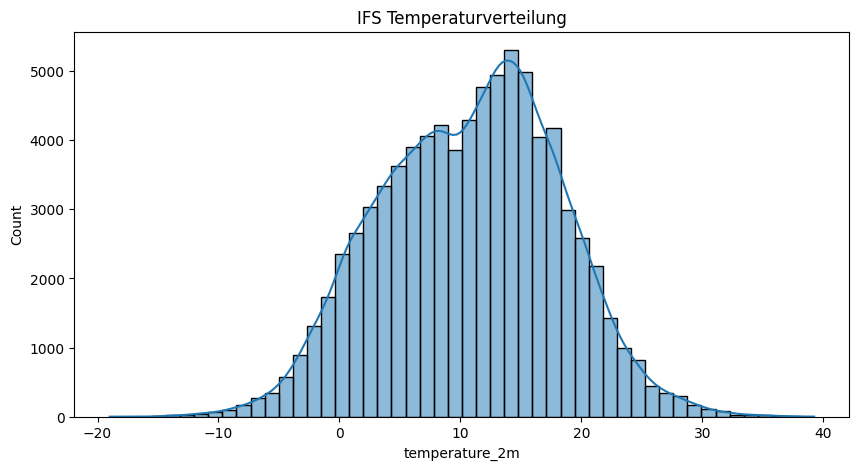

In [11]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["temperature_2m"],
    bins=50,
    kde=True
)

plt.title(
    "IFS Temperaturverteilung"
)
plt.show()

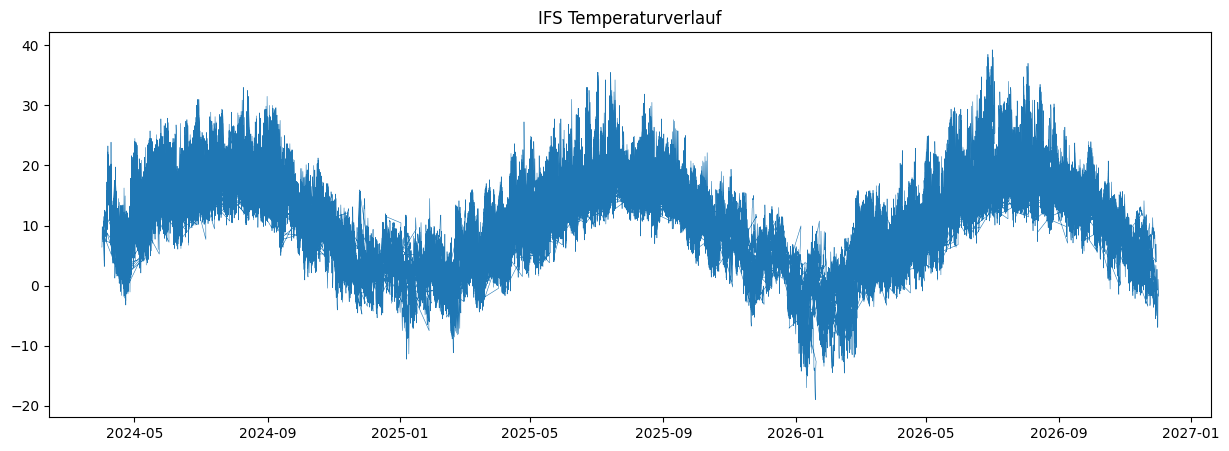

In [12]:
plt.figure(figsize=(15,5))

plt.plot(
    df["valid_time"],
    df["temperature_2m"],
    linewidth=0.4
)

plt.title(
    "IFS Temperaturverlauf"
)

plt.show()

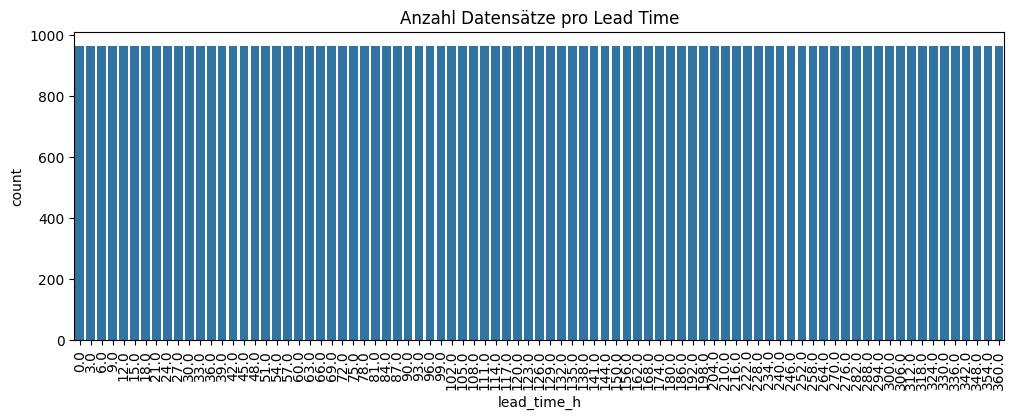

In [13]:
plt.figure(figsize=(12,4))

sns.countplot(
    x="lead_time_h",
    data=df
)

plt.xticks(rotation=90)

plt.title(
    "Anzahl Datensätze pro Lead Time"
)

plt.show()

Jede Lead Time kommt gleich oft vor (961-mal, einmal pro Lauf).

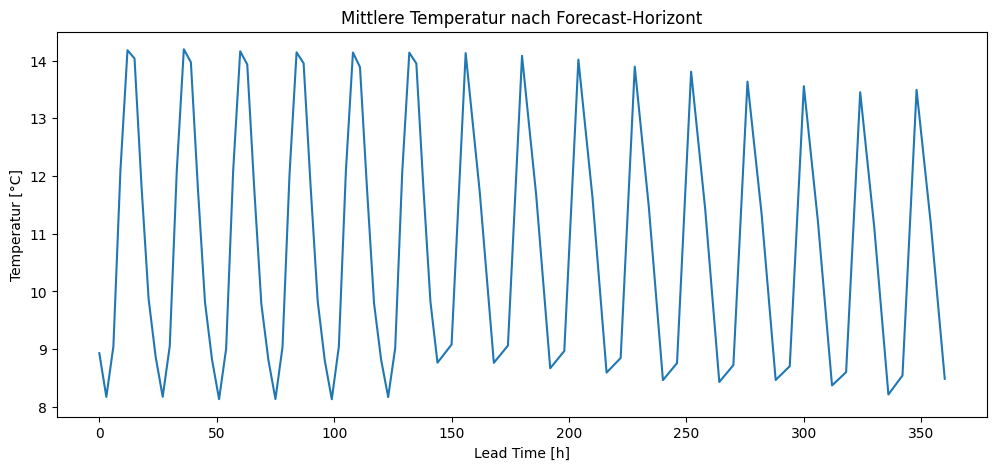

In [14]:
mean_by_lead = (
    df.groupby("lead_time_h")
      ["temperature_2m"]
      .mean()
)

plt.figure(figsize=(12,5))

mean_by_lead.plot()

plt.title(
    "Mittlere Temperatur nach Forecast-Horizont"
)

plt.xlabel("Lead Time [h]")
plt.ylabel("Temperatur [°C]")

plt.show()

Auch hier zackt die Kurve wegen der Tageszeit (Start immer 00 UTC, Erklärung in Notebook 02). Bis +144 h sind die
Zacken feiner, weil es dort 3-h-Schritte gibt.

Text(0.5, 1.0, 'Temperaturstreuung nach Lead Time')

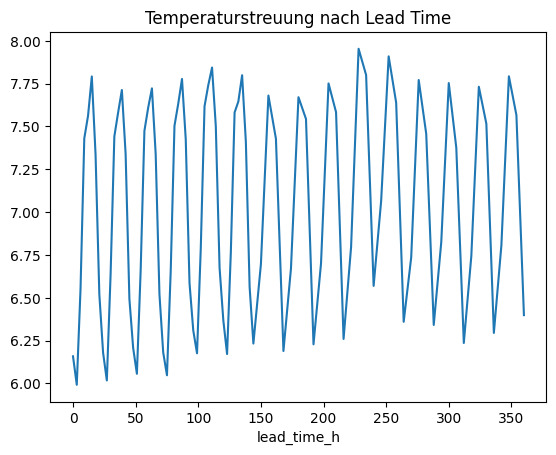

In [15]:
std_by_lead = (
    df.groupby("lead_time_h")
      ["temperature_2m"]
      .std()
)

std_by_lead.plot()

plt.title(
    "Temperaturstreuung nach Lead Time"
)

**Was der Plot zeigt:** Für jede Lead Time die Standardabweichung aller vorhergesagten Temperaturen. Sie misst, wie
stark die Vorhersagen schwanken. Darin steckt vor allem der Jahresgang, deshalb liegt sie bei 6–7 °C. Wenn ein Modell
bei langen Lead Times glättet, sinkt diese Streuung (ausführliche Erklärung in Notebook 02).

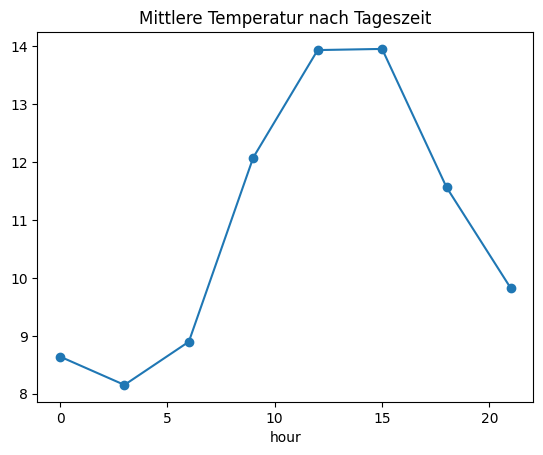

In [16]:
df["hour"] = (
    df["valid_time"]
      .dt.hour
)

hourly = (
    df.groupby("hour")
      ["temperature_2m"]
      .mean()
)

hourly.plot(marker="o")

plt.title(
    "Mittlere Temperatur nach Tageszeit"
)

plt.show()

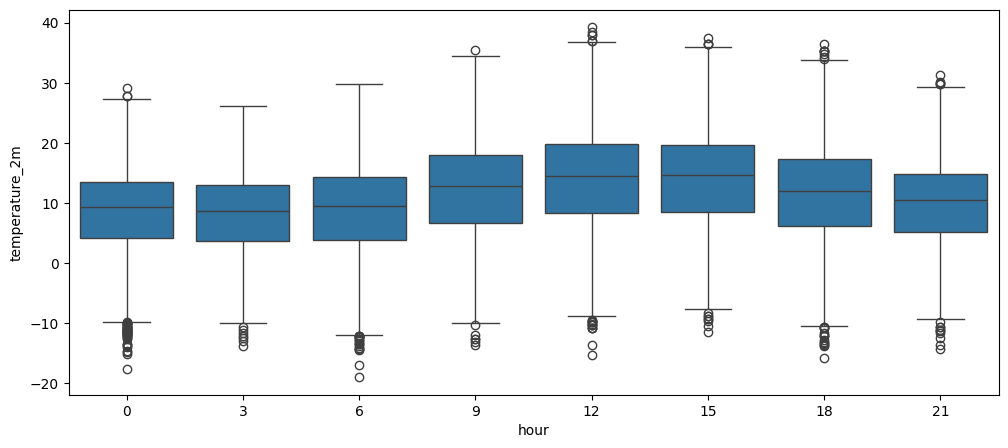

In [17]:
plt.figure(figsize=(12,5))

sns.boxplot(
    data=df,
    x="hour",
    y="temperature_2m"
)

plt.show()

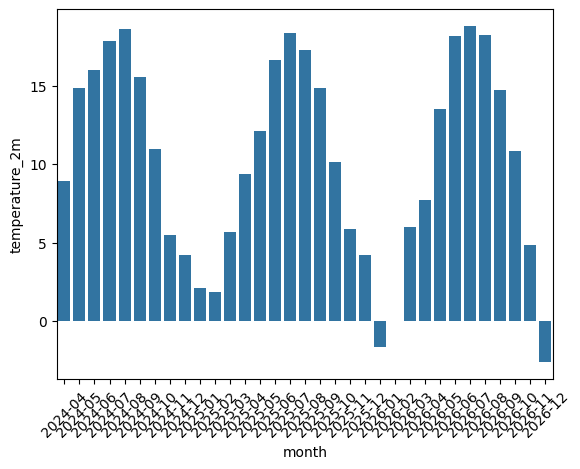

In [18]:
df["month"] = (
    df["valid_time"]
      .dt.to_period("M")
)

monthly = (
    df.groupby("month")
      ["temperature_2m"]
      .mean()
      .reset_index()
)

monthly["month"] = (
    monthly["month"]
    .astype(str)
)

sns.barplot(
    data=monthly,
    x="month",
    y="temperature_2m"
)

plt.xticks(rotation=45)

plt.show()

## Temperatur nach Monat und Tageszeit

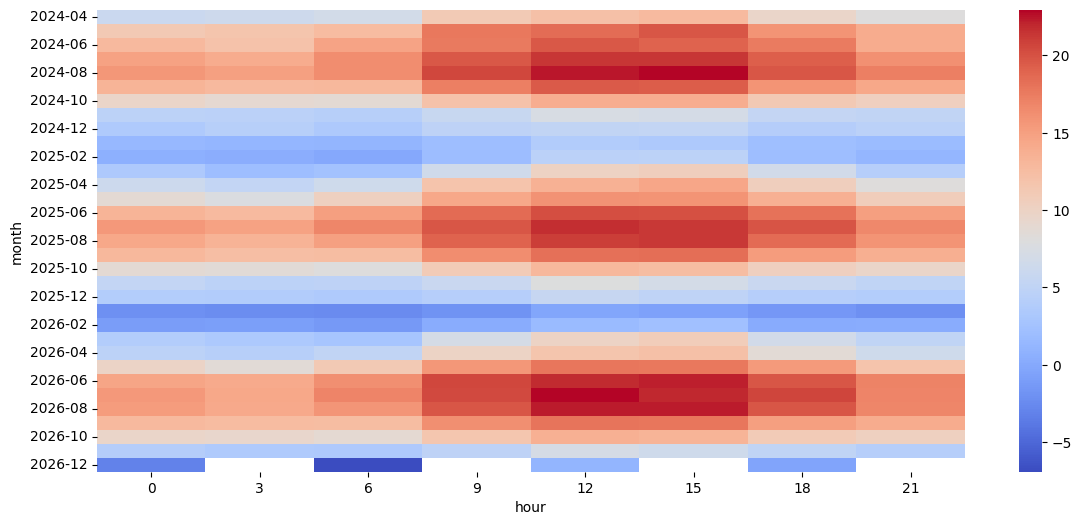

In [19]:
heatmap_data = (
    df.groupby(
        ["month","hour"]
    )["temperature_2m"]
    .mean()
    .unstack()
)

plt.figure(figsize=(14,6))

sns.heatmap(
    heatmap_data,
    cmap="coolwarm"
)

plt.show()

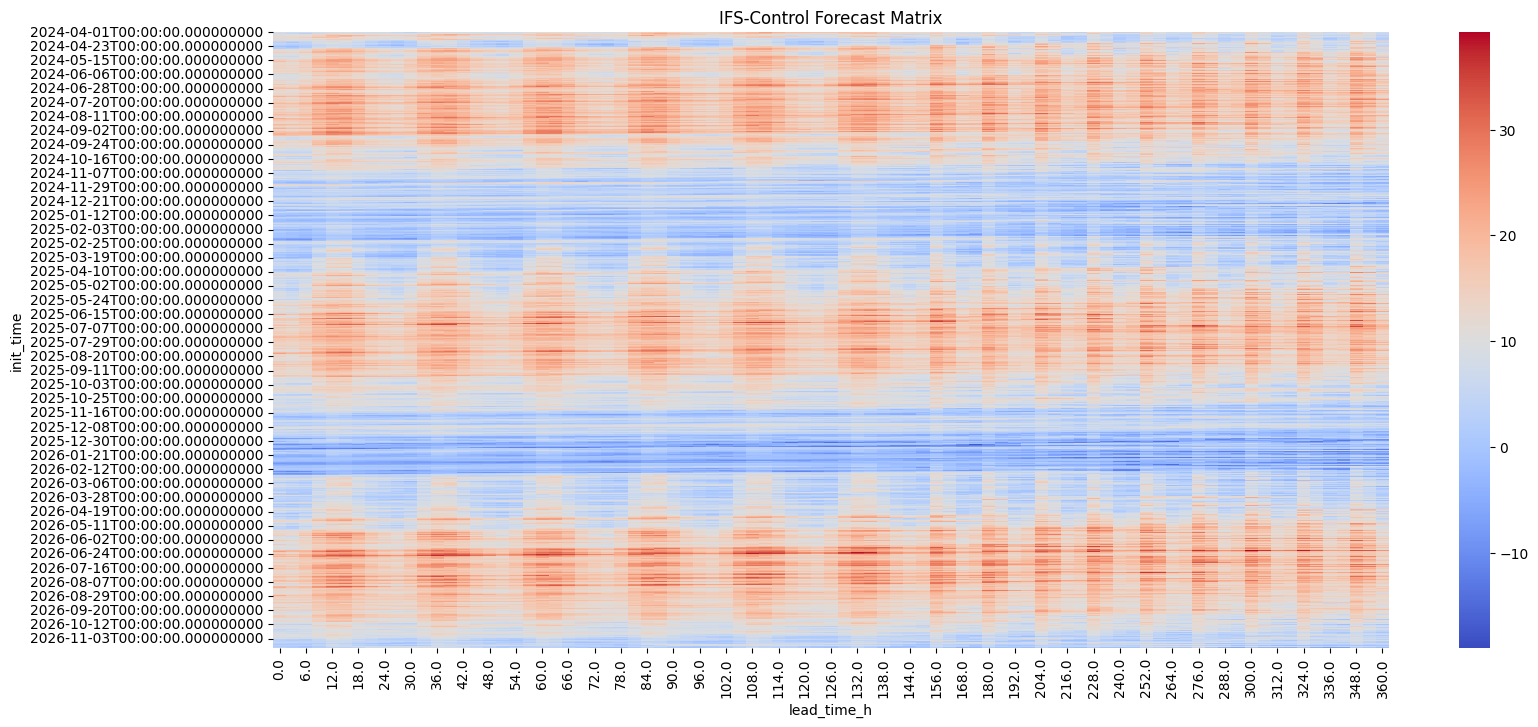

In [20]:
forecast_matrix = (
    df.pivot_table(
        index="init_time",
        columns="lead_time_h",
        values="temperature_2m"
    )
)

plt.figure(figsize=(18,8))

sns.heatmap(
    forecast_matrix,
    cmap="coolwarm"
)

plt.title(
    "IFS-Control Forecast Matrix"
)

plt.show()

**Forecast-Matrix:** Jede Zeile ist ein Lauf, jede Spalte eine Lead Time. Waagerechte Bänder = Jahreszeiten,
senkrechte Streifen = Tagesgang. Keine Lücken.

## Niederschlagsvorhersage

Die Rate (mm pro Sekunde) ist der Mittelwert über das Intervall **vor** dem Zeitpunkt. Bis +144 h ist ein Schritt 3 h lang, danach 6 h.
Deshalb rechnen wir mit der jeweiligen Schrittlänge: Menge = Rate × Schrittlänge in Sekunden. Danach summieren wir auf
6-h-Fenster, damit die Werte mit AIFS, GraphCast und DWD vergleichbar sind.

In [21]:
df = df.sort_values(["init_time", "lead_time_h"])

# Schrittlänge: Abstand zur vorherigen Lead Time
df["step_h"] = df.groupby("init_time")["lead_time_h"].diff()

# Rate (mm/s) mal Schrittlänge in Sekunden
df["precip_mm"] = df["precipitation_surface"] * df["step_h"] * 3600

df["step_h"].value_counts()

step_h
3.0    46128
6.0    34596
Name: count, dtype: int64

In [22]:
# Jeder Schritt gehört zum 6-h-Fenster, das bei ihm endet
df["window_end_h"] = np.ceil(df["lead_time_h"] / 6) * 6

precip_6h = (
    df[df["lead_time_h"] > 0]
      .groupby(["init_time", "window_end_h"])["precip_mm"]
      .sum()
      .reset_index()
)

exactly_zero = (precip_6h["precip_mm"] == 0).mean()
almost_dry = (precip_6h["precip_mm"] < 0.1).mean()

print(f"Genau 0 mm: {exactly_zero:.1%}")
print(f"Unter 0,1 mm (praktisch trocken): {almost_dry:.1%}")

precip_6h["precip_mm"].describe()

Genau 0 mm: 48.3%
Unter 0,1 mm (praktisch trocken): 65.2%


count    57660.000000
mean         0.548043
std          1.526942
min          0.000000
25%          0.000000
50%          0.015289
75%          0.305128
max         31.733323
Name: precip_mm, dtype: float64

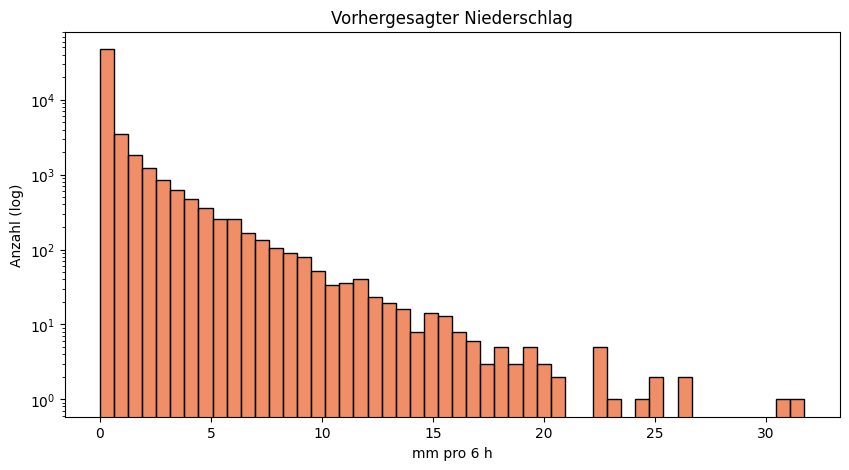

In [23]:
plt.figure(figsize=(10,5))

sns.histplot(
    precip_6h["precip_mm"],
    bins=50,
    color="#eb6834"
)

plt.yscale("log")
plt.title("Vorhergesagter Niederschlag")
plt.xlabel("mm pro 6 h")
plt.ylabel("Anzahl (log)")
plt.show()

IFS sagt in 48 % der 6-h-Fenster exakt 0 mm voraus (AIFS: 29 %, DWD: rund 75 % trocken). Das Physikmodell lässt also
seltener „ein bisschen“ regnen als das KI-Modell, ist aber immer noch deutlich nasser als die Messung.

## Erkenntnisse

- **Vollständig:** 961 Läufe, je 85 Lead Times (0–360 h), kein Tag fehlt.
- **Schrittweite wechselt** bei +144 h von 3 h auf 6 h. Beim Niederschlag mit der Schrittlänge rechnen.
- **Temperatur** zwischen −19 °C und 39,25 °C, plausibel. Tages- und Jahresgang wie erwartet.
- **Niederschlag:** häufiger exakt trocken als AIFS, aber seltener als die DWD-Messung.
- **Modellwechsel:** IFS Cycle 50r1 seit 12.05.2026 (gleichzeitig mit AIFS v2). Später prüfen, ob man das im Fehler sieht.